# An M-dwarf model atmosphere from first principles with Payne Zero

A model atmosphere gives temperature, pressure and composition as functions of depth in the thin outer layer of a star from which its light escapes. This notebook computes one for an M dwarf ($T_\mathrm{eff}$ = 3,700 K, $\log g$ = 4.5, solar composition) with Payne Zero's atmosphere solver. It shows each physical ingredient, how the solver iterates, how to check the result, and why the same procedure fails for a slightly cooler star.

The solver needs more than 15 GB of memory and runs for several minutes per iteration on one core, so the three runs used here were made on a compute cluster, each started from a MARCS structure. Their per-iteration records are in `examples/data/mdwarf_atmosphere/`, and this notebook reads them. Everything else runs on a laptop in about a minute.

In [1]:
import os

os.environ.setdefault("NUMBA_THREADING_LAYER", "workqueue")

import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy.ndimage import gaussian_filter1d

from payne_zero_synthesis import build_structured_atmosphere, synthesize

REPO = Path.cwd().resolve()
if not (REPO / "examples").is_dir():
    REPO = REPO.parent
DATA = REPO / "examples" / "data" / "mdwarf_atmosphere"


runs = {case: dict(np.load(DATA / f"{case}.npz")) for case in ("converged", "restart", "diverged")}
summaries = {case: json.loads((DATA / f"{case}.json").read_text()) for case in runs}
for case, summary in summaries.items():
    labels = summary["labels"]
    print(f"{case:9s} Teff {labels['effective_temperature']:.0f} K, log g {labels['log_surface_gravity']}: "
          f"{summary['iterations']} iterations, converged = {summary['converged']}")

ORANGE, BLUE, GREEN, INK, MUTED = "#d95f02", "#1f5fa8", "#1b8a5a", "#1a1a1a", "#7a7a7a"
plt.rcParams.update({"figure.dpi": 110, "xtick.direction": "in", "ytick.direction": "in",
                     "xtick.top": True, "ytick.right": True})
SIGMA_SB = 5.670374e-5  # erg cm^-2 s^-1 K^-4

converged Teff 3700 K, log g 4.5: 12 iterations, converged = True
restart   Teff 3700 K, log g 4.5: 4 iterations, converged = True
diverged  Teff 3500 K, log g 4.5: 40 iterations, converged = False


## 1. The physical problem

Payne Zero computes a one-dimensional, plane-parallel atmosphere in local thermodynamic equilibrium (LTE). The depth coordinate is the column mass $m$, the mass per unit area above a point (g cm⁻²); the unknown is $T(m)$ on 80 layers. Given $T(m)$, four pieces of physics fix everything else:

1. **Hydrostatic equilibrium.** $dP/dm = g$: the pressure at depth $m$ carries the weight of the gas above. Payne Zero integrates gas, radiation and turbulent pressure together.
2. **Equation of state and chemistry.** At each layer, $T$ and $P_\mathrm{gas}$ fix the number densities of all atoms, ions, molecules and free electrons, through the Saha equation and molecular dissociation equilibrium. In M dwarfs a large share of the hydrogen forms H₂, nearly all the carbon is in CO, and H₂O, OH and TiO are abundant enough to dominate the line opacity.
3. **Opacity and radiative transfer.** Continuous opacity (H⁻ dominates) plus millions of atomic and molecular lines give the absorption coefficient at each frequency. The transfer equation $\mu\, dI_\nu/d\tau_\nu = I_\nu - S_\nu$, with $S_\nu$ = $B_\nu(T)$ plus scattering, then gives the radiative flux $F_\mathrm{rad}(m)$ at every depth.
4. **Energy conservation.** In a static atmosphere no energy is created or lost, so the total flux is the same at every depth: $F_\mathrm{rad} + F_\mathrm{conv} = \sigma T_\mathrm{eff}^4$. Where the temperature gradient $\nabla = d\ln T/d\ln P$ exceeds the adiabatic gradient $\nabla_\mathrm{ad}$ (the Schwarzschild criterion), convection carries part of the flux; Payne Zero computes $F_\mathrm{conv}$ with mixing-length theory.

The first three give the flux for any trial $T(m)$. The fourth is the condition that $T(m)$ must satisfy. The solver iterates:

> trial $T(m)$ → pressure → chemistry → opacity → transfer and convection → **flux error** at each depth → temperature correction → new $T(m)$ on a fixed grid of Rosseland optical depth $\tau$ from $10^{-6.875}$ to $10^3$.

It stops when no layer's temperature changes by more than 5 × 10⁻⁴ (relative) in an iteration. The **flux error**, $(F_\mathrm{rad} + F_\mathrm{conv})/\sigma T_\mathrm{eff}^4 - 1$, is the direct measure of how far a structure is from energy balance.

## 2. The starting structure

The iteration needs a starting $T(m)$. Payne Zero's own initializers cover $T_\mathrm{eff}$ ≥ 4,000 K, so the start is the MARCS model for the same labels: its $T(m)$ is put on Payne Zero's 80 layers, and Payne Zero computes the pressure from hydrostatic equilibrium and the electron density from its own chemistry. Only the temperature structure comes from MARCS; the physics that decides the answer is Payne Zero's.

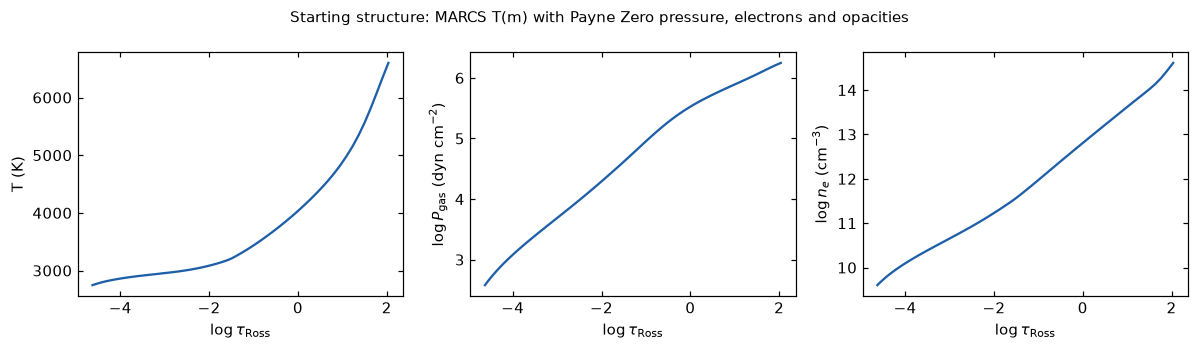

In [2]:
converged = runs["converged"]
# Rosseland optical depth of the starting structure, computed with Payne Zero's opacities in iteration 1.
log_tau = np.log10(converged["input_rosseland_optical_depth"][0])

fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
axes[0].plot(log_tau, converged["seed_temperature"], color=BLUE)
axes[0].set_ylabel("T (K)")
axes[1].plot(log_tau, np.log10(converged["seed_gas_pressure"]), color=BLUE)
axes[1].set_ylabel(r"$\log P_\mathrm{gas}$ (dyn cm$^{-2}$)")
axes[2].plot(log_tau, np.log10(converged["seed_electron_density"]), color=BLUE)
axes[2].set_ylabel(r"$\log n_e$ (cm$^{-3}$)")
for ax in axes:
    ax.set_xlabel(r"$\log \tau_\mathrm{Ross}$")
fig.suptitle("Starting structure: MARCS T(m) with Payne Zero pressure, electrons and opacities", fontsize=10)
fig.tight_layout()

The gas is cool, dense and almost neutral. Near $\tau_\mathrm{Ross}$ = 1 the gas pressure is a few times 10⁵ dyn cm⁻², and only about one particle in 10⁵ is a free electron, supplied by metals with low ionization potentials. Hydrogen is almost entirely neutral, so the main continuous opacity is H⁻, whose abundance scales with that small electron density.

## 3. Chemistry

The solver's molecular-equilibrium step returns the number density of every species in every layer. The plot shows the main molecules of the final model, relative to the total hydrogen density.

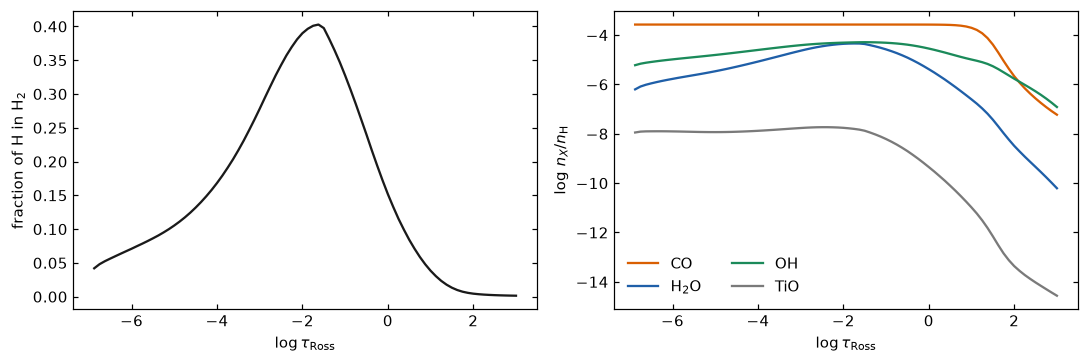

In [3]:
codes = converged["final_molecule_codes"][: converged["final_molecular_populations"].shape[1]]
population = converged["final_molecular_populations"]


def density(code):
    return population[:, int(np.flatnonzero(np.isclose(codes, code))[0])]


hydrogen = density(1.0) + 2.0 * density(101.0)
final_log_tau = np.log10(converged["standard_rosseland_optical_depth"][-1])
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].plot(final_log_tau, 2.0 * density(101.0) / hydrogen, color=INK)
axes[0].set(xlabel=r"$\log \tau_\mathrm{Ross}$", ylabel="fraction of H in H$_2$")
for name, code, color in [("CO", 608, ORANGE), ("H$_2$O", 10108, BLUE), ("OH", 108, GREEN), ("TiO", 822, MUTED)]:
    axes[1].plot(final_log_tau, np.log10(density(code) / hydrogen), color=color, label=name)
axes[1].set(xlabel=r"$\log \tau_\mathrm{Ross}$", ylabel=r"$\log\, n_X / n_\mathrm{H}$")
axes[1].legend(frameon=False, ncol=2)
fig.tight_layout()

Up to 40% of the hydrogen is bound in H₂ in the middle layers. CO holds nearly all the carbon and, since the solar C/O ratio is about 0.55, roughly half of the oxygen; OH and H₂O each take up to about a tenth of the oxygen. TiO is rare by number but has so many strong lines that it shapes the optical spectrum. The molecular lines, together with the H⁻ continuum, set the opacity, which is why an M-dwarf atmosphere cannot be computed without them, and why the carbon-to-oxygen ratio matters for the whole structure.

## 4. Iterating to a solution

The run starts from the structure above and iterates the solver until no layer's temperature changes by more than 5 × 10⁻⁴. The left panel follows the flux error; the right panel follows the largest temperature change.

stopped after 12 iterations: flux error p95 7.32%, median 0.008%, max 13.2%


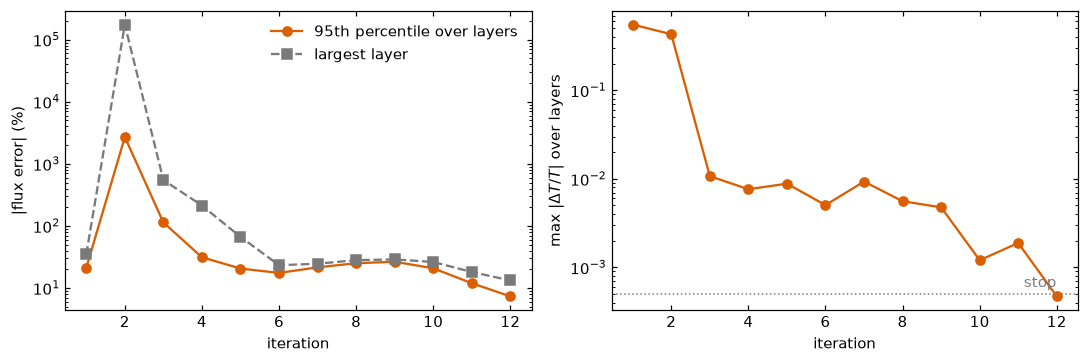

In [4]:
def flux_statistics(run):
    error = np.abs(run["flux_error_percent"])
    return np.percentile(error, 95, axis=1), np.median(error, axis=1), error.max(axis=1)


fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
p95, median, maximum = flux_statistics(converged)
iterations = np.arange(1, p95.size + 1)
axes[0].semilogy(iterations, p95, "o-", color=ORANGE, label="95th percentile over layers")
axes[0].semilogy(iterations, maximum, "s--", color=MUTED, label="largest layer")
axes[0].set(xlabel="iteration", ylabel="|flux error| (%)")
axes[0].legend(frameon=False)
axes[1].semilogy(iterations, converged["all_layer_change"], "o-", color=ORANGE)
axes[1].axhline(5e-4, color=MUTED, ls=":", lw=1)
axes[1].text(iterations[-1], 6e-4, "stop", ha="right", color=MUTED)
axes[1].set(xlabel="iteration", ylabel=r"max $|\Delta T/T|$ over layers")
fig.tight_layout()
print(f"stopped after {iterations[-1]} iterations: flux error p95 {p95[-1]:.2f}%, median {median[-1]:.3f}%, "
      f"max {maximum[-1]:.1f}%")

The first correction is large and overshoots: in iteration 2 the flux error jumps to thousands of per cent before the solver recovers. By iteration 12 the temperature has stopped changing. Measured on each structure's own optical-depth scale, the final $T(\tau)$ is close to the MARCS start; most of the change is at the top and bottom. The model has also grown: it now spans the full Rosseland depth grid, while in Payne Zero's opacities the MARCS start reached only from $\tau_\mathrm{Ross}$ ≈ 10⁻⁴·⁶ to 10². The flux error printed for an iteration is that of the structure the iteration started from, so the last value still carries the final correction's residue.

The panel below shows how $T(\tau)$ evolves, and the flux error by depth at the start and at the end.

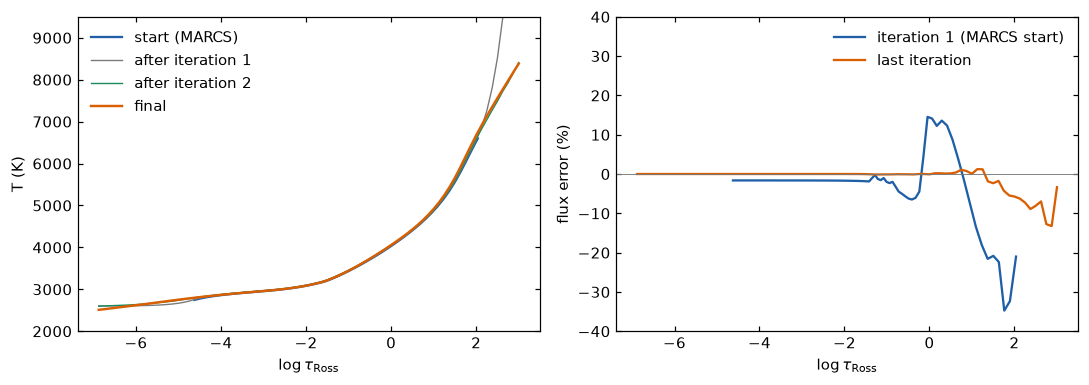

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].plot(log_tau, converged["seed_temperature"], color=BLUE, label="start (MARCS)")  # its own tau scale
for k, color in [(0, MUTED), (1, GREEN)]:
    axes[0].plot(np.log10(converged["standard_rosseland_optical_depth"][k]), converged["state_temperature"][k],
                 color=color, lw=0.9, label=f"after iteration {k + 1}")
axes[0].plot(final_log_tau, converged["state_temperature"][-1], color=ORANGE, lw=1.6, label="final")
axes[0].set(xlabel=r"$\log \tau_\mathrm{Ross}$", ylabel="T (K)", ylim=(2000, 9500))
axes[0].legend(frameon=False)
for k, color, label in [(0, BLUE, "iteration 1 (MARCS start)"), (-1, ORANGE, "last iteration")]:
    axes[1].plot(np.log10(converged["input_rosseland_optical_depth"][k]), converged["flux_error_percent"][k],
                 color=color, label=label)
axes[1].axhline(0.0, color=MUTED, lw=0.6)
axes[1].set(xlabel=r"$\log \tau_\mathrm{Ross}$", ylabel="flux error (%)", ylim=(-40, 40))
axes[1].legend(frameon=False)
fig.tight_layout()

## 5. Convection

Below $\tau_\mathrm{Ross}$ ≈ 0.04 the temperature gradient $\nabla$ exceeds $\nabla_\mathrm{ad}$ and the gas convects, well above the layers where the continuum forms. Convection carries about 40% of the flux at $\tau_\mathrm{Ross}$ = 1 and about 85% at $\tau_\mathrm{Ross}$ = 10–100. In the deep layers convection is efficient, and $\nabla$ stays within about 0.05 of $\nabla_\mathrm{ad}$.

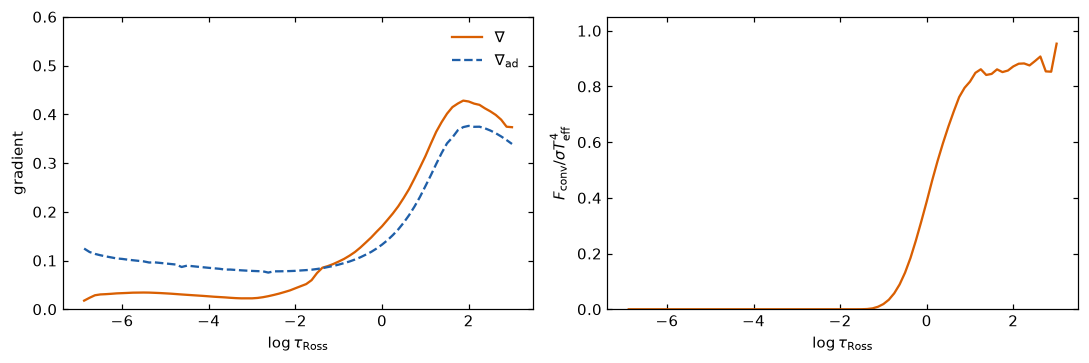

In [6]:
teff = summaries["converged"]["labels"]["effective_temperature"]
eddington_flux = SIGMA_SB * teff**4 / (4.0 * np.pi)  # Payne Zero stores Eddington fluxes, F/(4 pi)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].plot(final_log_tau, converged["final_gradient"], color=ORANGE, label=r"$\nabla$")
axes[0].plot(final_log_tau, converged["final_adiabatic_gradient"], color=BLUE, ls="--", label=r"$\nabla_\mathrm{ad}$")
axes[0].set(xlabel=r"$\log \tau_\mathrm{Ross}$", ylabel="gradient", ylim=(0, 0.6))
axes[0].legend(frameon=False)
input_log_tau = np.log10(converged["input_rosseland_optical_depth"][-1])
axes[1].plot(input_log_tau, converged["convective_flux"][-1] / eddington_flux, color=ORANGE)
axes[1].set(xlabel=r"$\log \tau_\mathrm{Ross}$", ylabel=r"$F_\mathrm{conv} / \sigma T_\mathrm{eff}^4$", ylim=(0, 1.05))
fig.tight_layout()

## 6. Is it a solution?

The stop rule only says the iteration stopped moving. Two further checks are needed.

**Energy balance.** The final $T(m)$ is rebuilt from scratch (new pressure, new chemistry) and given one more solver iteration. The flux error of that iteration is compared with fixed limits, set once from earlier converged dwarf models and not adjusted since: 95th percentile ≤ 9.56%, median ≤ 0.234%, largest layer ≤ 23.2%. (The last value in Section 4, 7.3%, belongs to the structure before the final correction.)

**Restart.** That rebuilt structure is then iterated to convergence again. A genuine solution is reproduced in a few iterations.

In [7]:
GATE = {"p95": 9.557, "median": 0.2342, "max": 23.15}  # %

restart = runs["restart"]
p95, median, maximum = (values[0] for values in flux_statistics(restart))
passes = p95 <= GATE["p95"] and median <= GATE["median"] and maximum <= GATE["max"]
print(f"energy balance of the solution: p95 {p95:.2f}%, median {median:.3f}%, max {maximum:.1f}%  -> "
      f"{'passes' if passes else 'fails'}")
p95_end = flux_statistics(restart)[0][-1]
print(f"restart: converged after {restart['all_layer_change'].size} iterations, final p95 {p95_end:.2f}%")

mass_c, temperature_c = converged["state_column_mass"][-1], converged["state_temperature"][-1]
mass_r, temperature_r = restart["state_column_mass"][-1], restart["state_temperature"][-1]
common = (mass_c >= mass_r.min()) & (mass_c <= mass_r.max())
difference = np.abs(temperature_c[common] / np.interp(np.log(mass_c[common]), np.log(mass_r), temperature_r) - 1.0)
print(f"restart vs first solution: |dT/T| 95th percentile {np.percentile(difference, 95):.1e}, max {difference.max():.1e}")

energy balance of the solution: p95 4.94%, median 0.009%, max 9.5%  -> passes
restart: converged after 4 iterations, final p95 1.12%
restart vs first solution: |dT/T| 95th percentile 6.1e-04, max 1.6e-03


The solution passes, and the restart lands on the same structure to about 6 × 10⁻⁴ (95th percentile of $|\Delta T/T|$), with the flux error down to about 1%.

The solution can also be compared with the MARCS model it started from. Both are 1D LTE models with mixing-length convection; they differ in opacities, chemistry and numerical details. At equal column mass the two agree to 0.2% above $\tau_\mathrm{Ross}$ ≈ 0.1; deeper, the Payne Zero model is warmer, by about 1% at $\tau_\mathrm{Ross}$ = 1 and 4% at 100.

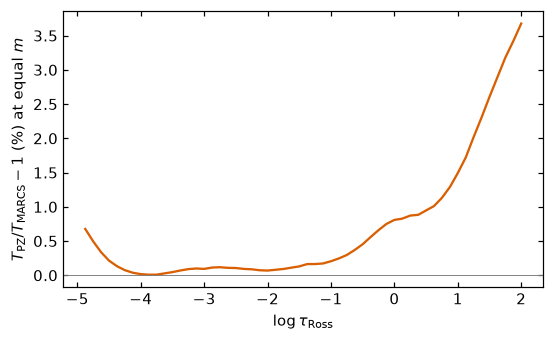

In [8]:
mass_s, temperature_s = converged["seed_column_mass"], converged["seed_temperature"]
overlap = (mass_c >= mass_s.min()) & (mass_c <= mass_s.max())  # the Payne Zero model extends higher and deeper
marcs_temperature = np.interp(np.log(mass_c[overlap]), np.log(mass_s), temperature_s)
fig, ax = plt.subplots(figsize=(5, 3.2))
ax.plot(final_log_tau[overlap], 100.0 * (temperature_c[overlap] / marcs_temperature - 1.0), color=ORANGE)
ax.axhline(0.0, color=MUTED, lw=0.6)
ax.set(xlabel=r"$\log \tau_\mathrm{Ross}$", ylabel=r"$T_\mathrm{PZ}/T_\mathrm{MARCS} - 1$ (%) at equal $m$")
fig.tight_layout()

## 7. The spectrum

The converged atmosphere is a complete Payne Zero product and goes straight into `synthesize`. Below it is compared with the spectrum computed on the MARCS structure (the route used in `mdwarf_apogee_fit.ipynb`) in an APOGEE window and in a TiO band. Both are smoothed to the instrument's resolution.

APOGEE H band: RMS difference 0.0010, max 0.0044


TiO: RMS difference 0.0020, max 0.0032


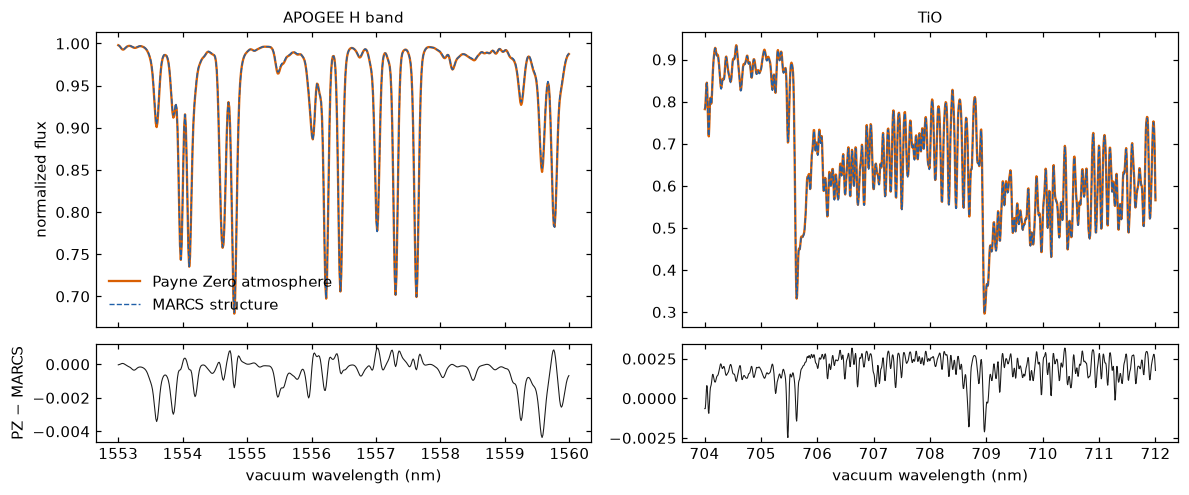

In [9]:
def smooth(spectrum, resolving_power):
    step = np.mean(np.diff(np.log(spectrum.wavelength_nm)))
    sigma = 1.0 / (resolving_power * 2.0 * np.sqrt(2.0 * np.log(2.0))) / step
    return (gaussian_filter1d(spectrum.flux_total, sigma, mode="nearest")
            / gaussian_filter1d(spectrum.flux_continuum, sigma, mode="nearest"))


structures = np.load(REPO / "examples" / "data" / "mdwarf_marcs_structures_v1.npz")
node = (np.flatnonzero(structures["metallicity"] == 0.0)[0], np.flatnonzero(structures["log_surface_gravity"] == 4.5)[0],
        np.flatnonzero(structures["effective_temperature"] == 3700.0)[0])
with np.load(DATA / "converged_atmosphere.npz") as product:
    abundances = product["elemental_abundances"].copy()
marcs_atmosphere = build_structured_atmosphere(
    **{name: structures[name][node] for name in ("temperature", "column_mass", "gas_pressure", "electron_density")},
    elemental_abundances=abundances, microturbulence=1.0e5, device="cpu")

WINDOWS = {"APOGEE H band": (1553.0, 1560.0, 120_000, 22_500), "TiO": (704.0, 712.0, 100_000, 20_000)}
fig, axes = plt.subplots(2, 2, figsize=(11, 4.6), gridspec_kw={"height_ratios": [3, 1]}, sharex="col")
for column, (name, (lo, hi, grid, instrument_r)) in enumerate(WINDOWS.items()):
    kwargs = dict(wavelength_start_nm=lo, wavelength_end_nm=hi, resolution=grid, device="cpu")
    payne = synthesize(DATA / "converged_atmosphere.npz", **kwargs)
    marcs = synthesize(marcs_atmosphere, **kwargs)
    flux_p, flux_m = smooth(payne, instrument_r), smooth(marcs, instrument_r)
    axes[0, column].plot(payne.wavelength_nm, flux_p, color=ORANGE, label="Payne Zero atmosphere")
    axes[0, column].plot(marcs.wavelength_nm, flux_m, color=BLUE, ls="--", lw=0.9, label="MARCS structure")
    axes[1, column].plot(payne.wavelength_nm, flux_p - flux_m, color=INK, lw=0.7)
    axes[0, column].set_title(name, fontsize=10)
    axes[1, column].set_xlabel("vacuum wavelength (nm)")
    print(f"{name}: RMS difference {np.sqrt(np.mean((flux_p - flux_m) ** 2)):.4f}, max {np.abs(flux_p - flux_m).max():.4f}")
axes[0, 0].set_ylabel("normalized flux")
axes[1, 0].set_ylabel("PZ − MARCS")
axes[0, 0].legend(frameon=False, loc="lower left")
fig.tight_layout()

The two structures give nearly the same spectrum: about 0.001 RMS in the H band and 0.002 in the TiO band, with the largest differences in line cores. This is why the MARCS structure is a usable stand-in where Payne Zero's own atmosphere does not converge.

## 8. When the iteration fails: 3,500 K

The same procedure at $T_\mathrm{eff}$ = 3,500 K, 200 K cooler and otherwise identical, does not converge.

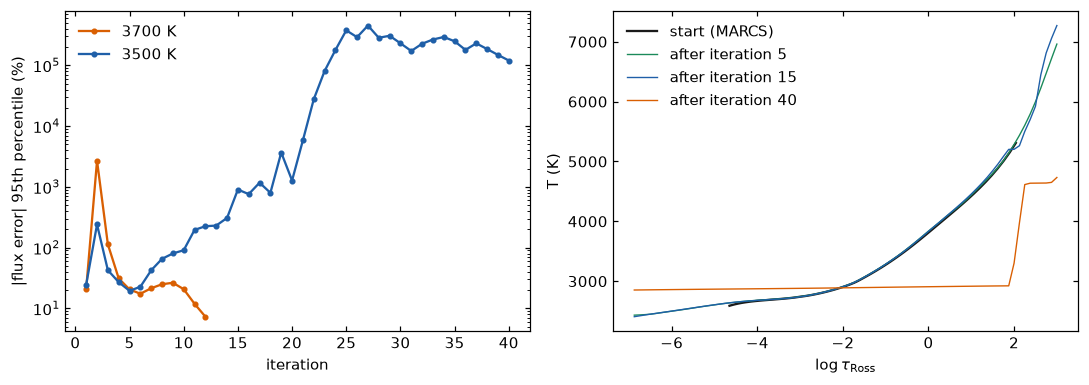

In [10]:
diverged = runs["diverged"]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for case, color in [("converged", ORANGE), ("diverged", BLUE)]:
    p95 = flux_statistics(runs[case])[0]
    teff_case = summaries[case]["labels"]["effective_temperature"]
    axes[0].semilogy(np.arange(1, p95.size + 1), p95, "o-", ms=3, color=color, label=f"{teff_case:.0f} K")
axes[0].set(xlabel="iteration", ylabel="|flux error| 95th percentile (%)")
axes[0].legend(frameon=False)
log_tau_d = np.log10(diverged["standard_rosseland_optical_depth"])
axes[1].plot(np.log10(diverged["input_rosseland_optical_depth"][0]), diverged["seed_temperature"], color=INK,
             label="start (MARCS)")
for k, color in [(4, GREEN), (14, BLUE), (len(log_tau_d) - 1, ORANGE)]:
    axes[1].plot(log_tau_d[k], diverged["state_temperature"][k], color=color, lw=0.9, label=f"after iteration {k + 1}")
axes[1].set(xlabel=r"$\log \tau_\mathrm{Ross}$", ylabel="T (K)")
axes[1].legend(frameon=False)
fig.tight_layout()

The flux error first behaves as at 3,700 K and drops to about 20% by iteration 5. It then creeps back up. From about iteration 15 the deep temperatures swing up and down from one iteration to the next with growing amplitude, and the flux error grows by orders of magnitude. By iteration 40 everything above $\tau_\mathrm{Ross}$ ≈ 75 has become nearly isothermal at about 2,900 K, which no balanced atmosphere at this $T_\mathrm{eff}$ has.

This is a failure of the iteration, not evidence that no atmosphere exists at 3,500 K. Each iteration corrects the temperature from the local flux error. In the dense convective layers of an M dwarf that correction can overshoot: an error in the deep temperatures comes back in the next iteration with the opposite sign and a larger size. In a study of a 3,600 K dwarf with a variant of this solver, such a deep error grew about threefold per iteration. The 3,700 K run shows the same overshoot in its second iteration, but there the error is damped instead of amplified.

In the present code, MARCS-started runs converge only for some dwarfs between 3,400 and 4,000 K, and for none at 3,300 K or below. About half of the converged ones are themselves unstable to a small perturbation. Making the solver robust here is current research: Anderson acceleration and a closure at the bottom boundary are being tested. Until then, the practical route for M-dwarf spectroscopy is a fixed MARCS temperature structure with Payne Zero chemistry and synthesis, as in `mdwarf_apogee_fit.ipynb`.

## 9. Things to try

- Plot the 3,500 K temperature at a deep layer (say layer 70) against iteration number. When do the swings start?
- Compare the converged structure with MARCS in pressure and electron density as well as temperature.

## Limitations

- 1D, LTE, mixing-length convection with one mixing length; no magnetic fields, no 3D convection.
- The convergence test is on the temperature change; energy balance is checked separately with fixed limits that allow a percent-level flux error in the 95th percentile.
- The three runs were made with a development version of the solver; results at other labels depend on the starting structure and can change with solver development.